# B1 – Forward : couches, réseau complet, binary cross-entropy
Ce notebook teste les briques de `src/layers.py`, `src/losses.py` et `src/model.py`.

**Convention** : un batch `X` a la forme `(n, d)`. Les poids suivent la notation du sujet, `W^(l)` de forme `(n_out, n_in)`, donc `Z = X @ W.T + b` (équivalent à `z = W x + b` pour une observation).

Architecture : $2 \to 16 \to 8 \to 1$ avec ReLU, ReLU, Sigmoid.

In [1]:
%load_ext autoreload
%autoreload 2

import sys; sys.path.append("..")
import numpy as np
import matplotlib.pyplot as plt
from src.data import load_data
from src.layers import Linear, ReLU, Sigmoid
from src.losses import bce
from src.model import MLP

SEED = 42
data = load_data(seed=SEED)
X_train, y_train = data["X_train"], data["y_train"]

## 1. Couche affine : $z = Wx + b$

In [2]:
rng = np.random.default_rng(0)
lin = Linear(2, 16, rng)
Z = lin.forward(X_train[:5])
print("W :", lin.W.shape, "| b :", lin.b.shape, "| sortie :", Z.shape)
assert lin.W.shape == (16, 2) and Z.shape == (5, 16)

# Vérification manuelle sur UNE observation, avec la formule du sujet z = W x + b
x = X_train[0]
z_manual = lin.W @ x + lin.b
assert np.allclose(Z[0], z_manual)
print("Batch et formule z = Wx + b concordent.")

W : (16, 2) | b : (16,) | sortie : (5, 16)
Batch et formule z = Wx + b concordent.


## 2. ReLU

In [3]:
z = np.array([[-2.0, -0.5, 0.0, 0.5, 3.0]])
print("ReLU :", ReLU().forward(z))
assert np.array_equal(ReLU().forward(z), [[0, 0, 0, 0.5, 3.0]])

ReLU : [[0.  0.  0.  0.5 3. ]]


## 3. Sigmoïde (valeurs connues et stabilité numérique)

sigma(0) = [[0.5]]
grandes valeurs : [[0.00000000e+00 1.92874985e-22 5.00000000e-01 1.00000000e+00
  1.00000000e+00]]


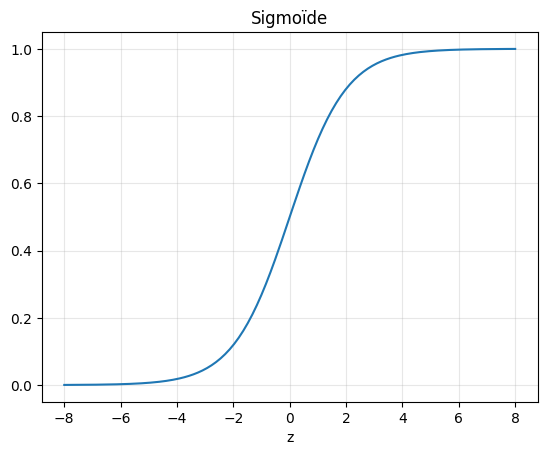

In [4]:
sig = Sigmoid()
print("sigma(0) =", sig.forward(np.array([[0.0]])))   # doit valoir 0.5

big = np.array([[-1000.0, -50.0, 0.0, 50.0, 1000.0]])  # exp(1000) déborderait sans version stable
out = sig.forward(big)
print("grandes valeurs :", out)
assert np.all(np.isfinite(out)) and np.all((out >= 0) & (out <= 1))

zz = np.linspace(-8, 8, 200)
plt.plot(zz, sig.forward(zz.reshape(1, -1)).ravel())
plt.title("Sigmoïde"); plt.xlabel("z"); plt.grid(alpha=.3); plt.show()

## 4. Binary cross-entropy
Valeurs de référence : si $\hat y = 0.5$, la perte vaut $\log 2 \approx 0.693$ quelle que soit la classe.

In [5]:
y = np.array([[1.0], [0.0]])
print("BCE(0.5) :", bce(np.array([[0.5], [0.5]]), y), "| log 2 =", np.log(2))
assert np.isclose(bce(np.array([[0.5], [0.5]]), y), np.log(2))

# Bonnes prédictions -> perte faible ; mauvaises -> perte élevée
print("bonne prédiction  :", bce(np.array([[0.99], [0.01]]), y))
print("mauvaise prédiction:", bce(np.array([[0.01], [0.99]]), y))

# Cas extrêmes : la perte doit rester finie (clipping)
extreme = bce(np.array([[0.0], [1.0]]), y)   # totalement faux, y_hat exactement 0 / 1
print("cas extrême (y_hat = 0 ou 1) :", extreme)
assert np.isfinite(extreme)

BCE(0.5) : 0.6931471805599453 | log 2 = 0.6931471805599453
bonne prédiction  : 0.01005033585350145
mauvaise prédiction: 4.605170185988091
cas extrême (y_hat = 0 ou 1) : 27.631032176910953


## 5. Réseau complet $2 \to 16 \to 8 \to 1$

In [6]:
model = MLP(sizes=(2, 16, 8, 1), seed=SEED)

for i, layer in enumerate(model.layers):
    extra = f"W {layer.W.shape}, b {layer.b.shape}" if isinstance(layer, Linear) else ""
    print(f"{i}: {type(layer).__name__:8s} {extra}")
print("Nombre de paramètres :", model.n_parameters())   # 2*16+16 + 16*8+8 + 8*1+1 = 193
assert model.n_parameters() == 193

0: Linear   W (16, 2), b (16,)
1: ReLU     
2: Linear   W (8, 16), b (8,)
3: ReLU     
4: Linear   W (1, 8), b (1,)
5: Sigmoid  
Nombre de paramètres : 193


In [7]:
y_hat = model.forward(X_train)
print("y_hat :", y_hat.shape, "| min/max :", y_hat.min().round(3), y_hat.max().round(3))
assert y_hat.shape == (X_train.shape[0], 1)
assert np.all((y_hat > 0) & (y_hat < 1))

# Vérification complète à la main (z1, a1, z2, a2, z3, y_hat) sur une observation
L1, L2, L3 = model.linear_layers()
x = X_train[0]
a1 = np.maximum(0, L1.W @ x + L1.b)
a2 = np.maximum(0, L2.W @ a1 + L2.b)
y0 = 1 / (1 + np.exp(-(L3.W @ a2 + L3.b)))
assert np.allclose(y_hat[0], y0)
print("Le forward du réseau correspond aux équations du sujet.")

y_hat : (900, 1) | min/max : 0.374 0.544
Le forward du réseau correspond aux équations du sujet.


## 6. Perte initiale
Avec une initialisation raisonnable, la sortie est proche de 0.5 et la perte initiale doit être de l'ordre de $\log 2 \approx 0.69$.

In [8]:
loss0 = bce(y_hat, y_train)
print(f"Loss initiale : {loss0:.4f}  (log 2 = {np.log(2):.4f})")
print(f"Accuracy initiale (train) : {model.accuracy(X_train, y_train):.3f}")
assert np.isfinite(loss0)

Loss initiale : 0.6711  (log 2 = 0.6931)
Accuracy initiale (train) : 0.600


## 7. Reproductibilité
Même graine donne les mêmes poids, donc la même sortie. C'est nécessaire pour comparer les optimiseurs à même initialisation (partie C).

In [9]:
m1, m2 = MLP(seed=SEED), MLP(seed=SEED)
assert np.allclose(m1.forward(X_train), m2.forward(X_train))
m3 = MLP(seed=SEED + 1)
assert not np.allclose(m1.forward(X_train), m3.forward(X_train))
print("OK : même seed = même réseau, seed différente = réseau différent.")

OK : même seed = même réseau, seed différente = réseau différent.


## Bilan J1 (partie forward)
- Dimensions cohérentes : `(n,2) → (n,16) → (n,8) → (n,1)`
- Loss finie, y compris dans les cas extrêmes
- Forward conforme aux équations du sujet

**Reste pour valider J1** : le backward et le gradient checking (notebook 03).